# 第三课：资金比例不等于风险比例

第二课已经把份额、现金、分红和交易记录连接起来。这一课在同一个账本上增加第一个动态配置方法。

**学习目标**：理解波动率、相关性、协方差；区分资金权重与风险贡献；理解反波动率配置为什么不保证风险平价；检查动态配置在相同条件下是否改善结果。

本节是历史研究，尚无收益预测或实盘建议。我们不会挑选表现最好的窗口：固定使用过去 **126 个交易日**（约半年）的收益，每月更新目标。126 是教学起点，不是已经证明最优的参数。

阅读顺序：风险概念 → 手算例子 → 真实历史风险分解 → 生成动态权重 → 公平回测 → 反思与练习。

In [1]:
from pathlib import Path
import sys, json, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
ROOT = Path.cwd()
if not (ROOT/'src').exists(): ROOT = ROOT.parent
sys.path.insert(0,str(ROOT/'src'))
from market_data import load_snapshot
from portfolio import simulate, reconcile
from risk_models import risk_contributions, inverse_vol_schedule
SNAPSHOT = __import__('os').environ.get('MARKET_LAB_SNAPSHOT', '20261007T234808781424Z')
LOOKBACK = 126
frames, manifest = load_snapshot(SNAPSHOT)
dates = frames['SPY'].index
assert all(f.index.equals(dates) for f in frames.values()), '日历不一致，先检查数据'
prices = pd.DataFrame({s:f['Adj Close'] for s,f in frames.items()})
OUT = ROOT/'reports'/('03_'+SNAPSHOT)
OUT.mkdir(parents=True,exist_ok=True)
plt.rcParams.update({'figure.figsize':(11,4),'axes.grid':True,'grid.alpha':.2})
print('沿用快照：',SNAPSHOT, '；数据截至',dates[-1].date())
print('数据没有重新下载；为了课程之间可复现比较，保留固定版本。')

沿用快照： 20261007T234808781424Z ；数据截至 2026-10-06
数据没有重新下载；为了课程之间可复现比较，保留固定版本。


## 1. 组合风险为什么不能简单加权？

**波动率**描述收益的起伏幅度。**相关性**描述两种资产收益共同变化的程度。**协方差**把两者结合：

$$\text{协方差}_{ij}=\text{相关性}_{ij}\times\text{波动率}_i\times\text{波动率}_j$$

两资产组合的方差（波动率的平方）为：

$$\sigma_p^2=w_A^2\sigma_A^2+w_B^2\sigma_B^2+2w_Aw_B\rho_{AB}\sigma_A\sigma_B$$

这里 $w$ 是资金权重，$\sigma$ 是波动率，$\rho$ 是相关性。最后一项解释了为什么分散效果依赖资产之间的关系。

**风险贡献**：在指定协方差模型下，把组合波动分解到各个资产。它不是亏损概率，也不是最大回撤贡献，更不是实际盈利贡献。

如果 $\Sigma$ 是协方差矩阵，则资产 $i$ 的波动贡献和占比分别为：

$$RC_i=\frac{w_i(\Sigma w)_i}{\sigma_p},\qquad \text{风险占比}_i=\frac{w_i(\Sigma w)_i}{\sigma_p^2}$$

各资产的 $RC_i$ 相加等于组合波动率，风险占比相加等于 100%。某些资产贡献可以为负：在该估计模型下起到抵消波动的作用，因此其他资产占比也可能超过 100%。不要把负值删掉再归一化。

这些是**过去数据给出的风险估计**，不是未来损失保证。

## 2. 先手算一个例子

假设 A 年化波动率为 20%，B 为 10%，两者相关性为 0。如果各投入一半资金，A 的风险占比是多少？

A 的方差项为 0.5² × 0.2² = 0.01；B 为 0.5² × 0.1² = 0.0025。A 占总方差的 80%，B 占 20%。**钱各一半，风险却不是各一半。**

反波动率配置使用 $w_i=(1/\sigma_i)/\sum_j(1/\sigma_j)$。本例 A 配三分之一、B 配三分之二，二者风险占比变为各一半。对三种或更多具有不同相关关系的资产，这个结论一般不成立。

In [2]:
toy_cov = pd.DataFrame(np.diag([.2**2,.1**2]),index=['A','B'],columns=['A','B'])
for label, weights in [('资金等权',{'A':.5,'B':.5}),('反波动率',{'A':1/3,'B':2/3})]:
    rc, vol = risk_contributions(weights,toy_cov)
    print(label, f'组合估计波动率 {vol:.2%}')
    display(rc.style.format('{:.2%}'))

资金等权 组合估计波动率 11.18%


,capital_weight,asset_volatility,volatility_contribution,risk_share
A,50.00%,20.00%,8.94%,80.00%
B,50.00%,10.00%,2.24%,20.00%


反波动率 组合估计波动率 9.43%


,capital_weight,asset_volatility,volatility_contribution,risk_share
A,33.33%,20.00%,4.71%,50.00%
B,66.67%,10.00%,4.71%,50.00%


## 3. 每次决策只能看当时已经有的数据

每月第一个观测日开盘执行；先取前一观测日收盘为止的最近 126 个日收益，估计年化协方差与波动率，再计算权重。

**预热期**：必须先积累 126 个收益，不能拿不足的数据装作半年估计。为公平比较，所有组合都从第一个有效执行日以同样本金重新开始。

研究风险使用调整后价格收益，执行账本仍使用实际价格和独立分红。当前快照可能包含数据供应商事后修订，按时间切片并不等于拥有严格的历史时点数据库。

下表记录每个目标的决策日期、执行日期、窗口起点、观测数和资产权重。这也是未来其他模型需要提供的可审查输出。

In [3]:
schedule, audit = inverse_vol_schedule(prices,lookback=LOOKBACK)
schedule.to_csv(OUT/'target_schedule.csv')
audit.to_csv(OUT/'risk_audit.csv',index=False)
START = schedule.index[0]
print('共同回测开始：',START.date(),'；结束：',dates[-1].date())
print('月度目标次数：',len(schedule))
display(schedule.head(3).round(4))
assert (schedule.decision_date.to_numpy() < schedule.index.to_numpy()).all()
assert (schedule.observations == LOOKBACK).all()
print('全部决策日期早于执行日期，全部窗口包含126个收益。')

共同回测开始： 2010-08-02 ；结束： 2026-10-06
月度目标次数： 195


,decision_date,window_start,observations,SPY,IEF,GLD
execution_date,,,,,,
2010-08-02,2010-07-30,2010-02-01,126,0.1903,0.5870,0.2227
2010-09-01,2010-08-31,2010-03-04,126,0.1904,0.5562,0.2534
2010-10-01,2010-09-30,2010-04-05,126,0.1869,0.5384,0.2747


全部决策日期早于执行日期，全部窗口包含126个收益。


## 4. 在真实历史窗口中，60/40 的风险如何分配？

下面选择**首次有效决策**，用同一个协方差估计比较三种目标配置。只使用当时以前的数据；不是拿全历史估计指导过去的交易。

`capital_weight` 是资金比例，`asset_volatility` 是资产估计年化波动，`volatility_contribution` 是对组合波动的贡献，`risk_share` 是风险贡献占比。

这是目标组合在决策时的估计，不是每天实际漂移持仓的风险。风险贡献属于这个窗口，不能永久贴在某项资产上。

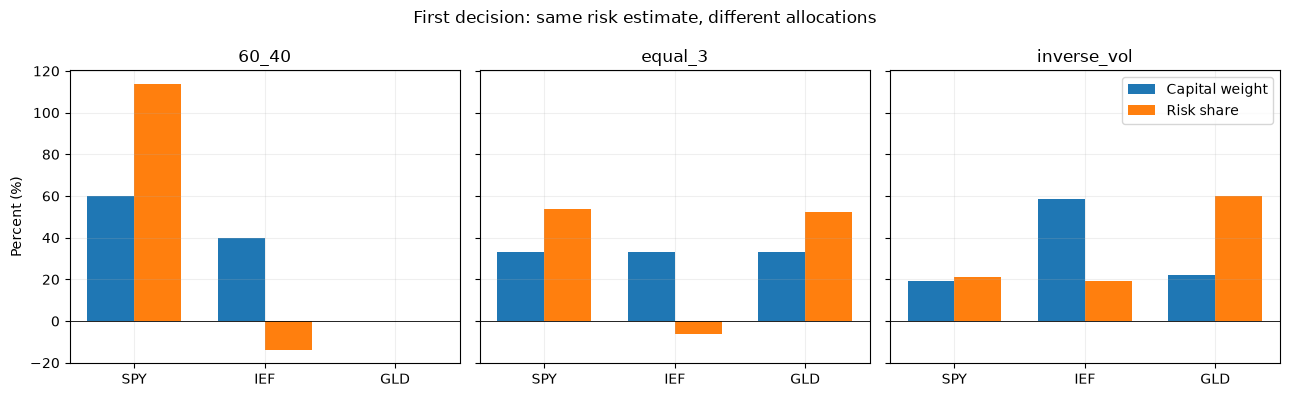

最后一次历史目标（不是当前买卖建议）：


,decision_date,capital_weight,risk_share
asset,,,
SPY,2026-09-30,0.251798,0.343526
IEF,2026-09-30,0.618843,0.329029
GLD,2026-09-30,0.129359,0.327445


In [4]:
first = audit[audit.execution_date == START].copy()
display(first[['policy','asset','capital_weight','asset_volatility','risk_share']]
        .set_index(['policy','asset']).style.format('{:.2%}'))
fig, axes = plt.subplots(1,3,figsize=(13,4),sharey=True)
for ax,name in zip(axes,['60_40','equal_3','inverse_vol']):
    a = first[first.policy == name].set_index('asset')
    x = np.arange(len(a))
    ax.bar(x-.18,a.capital_weight*100,.36,label='Capital weight')
    ax.bar(x+.18,a.risk_share*100,.36,label='Risk share')
    ax.set_xticks(x,a.index); ax.axhline(0,color='black',linewidth=.6); ax.set_title(name)
axes[0].set_ylabel('Percent (%)'); axes[-1].legend()
fig.suptitle('First decision: same risk estimate, different allocations')
fig.tight_layout(); fig.savefig(OUT/'01_risk_contributions.png',dpi=150); plt.show()
last = audit[(audit.execution_date == schedule.index[-1]) & (audit.policy == 'inverse_vol')]
print('最后一次历史目标（不是当前买卖建议）：')
display(last[['decision_date','asset','capital_weight','risk_share']].set_index('asset'))

## 5. 反波动率不是完整的风险平价

反波动率只根据各资产自己的波动率配钱；上面的风险贡献计算还用了相关性。如果两种资产经常同涨同跌，它们对整个组合的影响会相互增强。

完整的等风险贡献配置，需要结合协方差求解目标权重，让风险占比尽量接近。我们暂时不引入优化器，先确认简单方法到底改变了什么。

还要注意：低历史波动资产可能获得很高资金权重。**低波动不等于不会亏损，配置规则也没有最大亏损保证。** 本课没有单资产权重上限或目标波动率控制，后续可以单独研究这些约束。

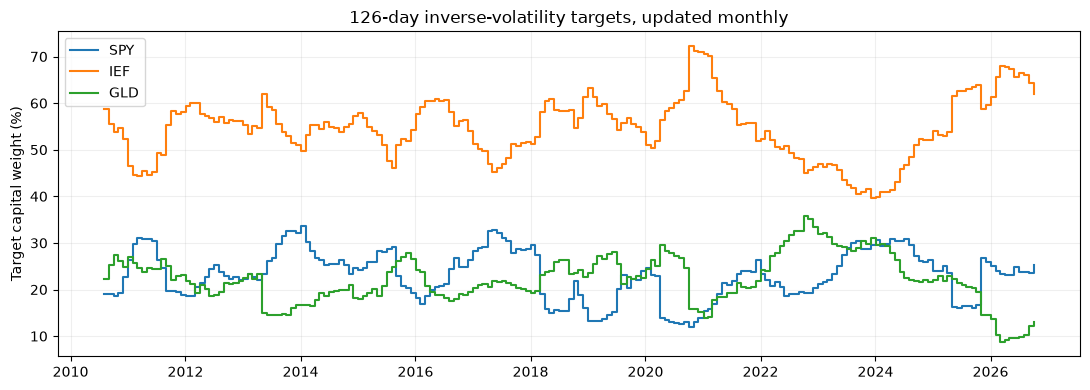

,SPY,IEF,GLD
min,11.94%,39.54%,8.82%
mean,23.17%,54.66%,22.17%
max,33.59%,72.24%,35.71%


这里的均值按月度决策等权计算，不是每日实际持仓均值。


In [5]:
fig,ax = plt.subplots()
for s in prices.columns:
    ax.step(schedule.index,schedule[s]*100,where='post',label=s)
ax.set(ylabel='Target capital weight (%)',title='126-day inverse-volatility targets, updated monthly')
ax.legend(); fig.tight_layout(); fig.savefig(OUT/'02_dynamic_weights.png',dpi=150); plt.show()
display(schedule[list(prices.columns)].agg(['min','mean','max']).style.format('{:.2%}'))
print('这里的均值按月度决策等权计算，不是每日实际持仓均值。')

## 6. 在第二课的同一个账本上执行

三个组合都使用：相同起止日期、初始 100,000 美元、月度开盘调仓、单边 5 bps（0.05%）成本、零碎份额、无杠杆、现金零利息、除息日立即计入分红现金的简化规则。

这次三者都会在调仓时重新投入分红，不使用上一课的 hold 版本。三资产等权是评估新方法的主要对照，60/40 提供另一种常见配置参照。

**重要：三者并非相同风险水平。** 收益高低可能来自不同的资产敞口，不能把收益差直接叫作 alpha。第二课起始日更早，也不能直接拿它的年化数字比较。

目标在前一日生成，执行仍是按当日开盘价格精确计算零碎份额并成交的理想化模型；没有模拟真实开盘订单提前报量、分批成交、税费和到账结算。

,期末资产($),年化收益,年化波动,最大回撤,累计费用($),交易天数
60_40,"450,387.42",9.75%,9.74%,-21.20%,440.13,195
equal_3,"374,369.24",8.50%,8.52%,-17.01%,481.37,195
inverse_vol,"269,694.34",6.32%,6.51%,-17.33%,706.18,195


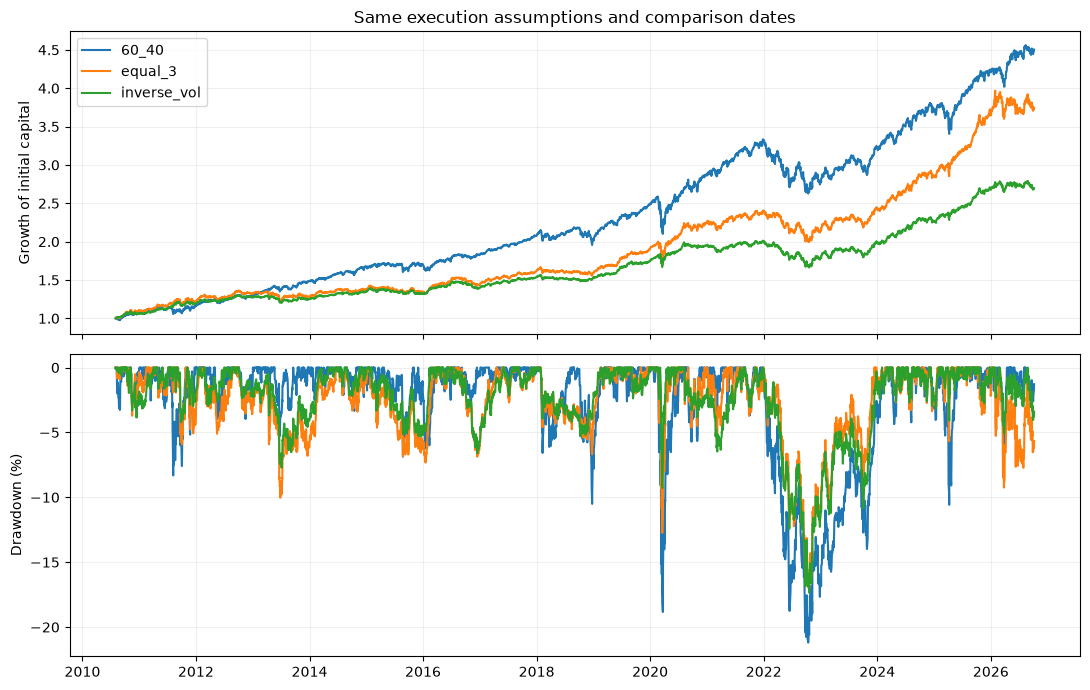

In [6]:
trading_frames = {s:f.loc[START:].copy() for s,f in frames.items()}
targets = {'60_40':{'SPY':.6,'IEF':.4},
           'equal_3':dict.fromkeys(prices.columns,1/3),
           'inverse_vol':schedule.iloc[0][list(prices.columns)].to_dict()}
results = {name:simulate(trading_frames,w,
               target_schedule=schedule if name=='inverse_vol' else None)
           for name,w in targets.items()}
for name,r in results.items():
    r.daily.to_csv(OUT/(name+'_daily.csv'))
    r.trades.to_csv(OUT/(name+'_trades.csv'),index=False)
    r.distributions.to_csv(OUT/(name+'_distributions.csv'),index=False)
metrics = pd.DataFrame({name:r.metrics() for name,r in results.items()}).T
metrics.to_csv(OUT/'metrics.csv')
display(metrics[['final_nav','cagr','annual_volatility','max_drawdown','fees_paid','trade_days']]
        .rename(columns={'final_nav':'期末资产($)','cagr':'年化收益','annual_volatility':'年化波动',
                         'max_drawdown':'最大回撤','fees_paid':'累计费用($)','trade_days':'交易天数'})
        .style.format({'期末资产($)':'{:,.2f}','年化收益':'{:.2%}','年化波动':'{:.2%}',
                       '最大回撤':'{:.2%}','累计费用($)':'{:,.2f}','交易天数':'{:.0f}'}))
fig,axes = plt.subplots(2,1,figsize=(11,7),sharex=True)
for name,r in results.items():
    nav=r.daily.nav
    peak=np.maximum.accumulate(np.r_[100000,nav.to_numpy()])[1:]
    axes[0].plot(nav.index,nav/100000,label=name)
    axes[1].plot(nav.index,(nav/peak-1)*100,label=name)
axes[0].set(ylabel='Growth of initial capital',title='Same execution assumptions and comparison dates')
axes[0].legend(); axes[1].set(ylabel='Drawdown (%)')
fig.tight_layout(); fig.savefig(OUT/'03_comparison.png',dpi=150); plt.show()

## 7. 看完整路径，不只看一个年化数字

年度表能帮助发现：看起来总体稳定的方法，是否在某些年份集中亏损。首尾年并非完整年份，会标注“部分”。

本课没有搜索最优参数，也没有预留完全未看过的历史测试集；这是按时间推进的历史对照实验，尚不构成独立验证后的投资优势。风险预测是否准确，需要另外把每次预测与其后实际波动比较，不能只看组合净值。

In [7]:
annual = {}
for name,r in results.items():
    ends = r.daily.nav.resample('YE').last()
    prior = ends.shift(1); prior.iloc[0] = 100000
    annual[name] = ends/prior-1
annual=pd.DataFrame(annual)
annual.index = [str(d.year)+('（部分）' if d.year in {START.year,dates[-1].year} else '') for d in annual.index]
annual.to_csv(OUT/'annual_returns.csv')
display(annual.style.format('{:.2%}'))
base, model = metrics.loc['equal_3'], metrics.loc['inverse_vol']
display(Markdown(f"相对三资产等权，反波动率的年化收益相差 **{(model.cagr-base.cagr)*100:+.2f} 个百分点**，年化波动相差 **{(model.annual_volatility-base.annual_volatility)*100:+.2f} 个百分点**。最大回撤分别为 **{model.max_drawdown:.2%} / {base.max_drawdown:.2%}**。降低日常波动不保证改善最深回撤，也不证明产生了 alpha。"))

,60_40,equal_3,inverse_vol
2010（部分）,7.71%,10.54%,7.11%
2011,7.67%,9.91%,11.32%
2012,11.19%,8.95%,7.08%
2013,15.56%,-3.12%,-2.11%
2014,11.78%,6.85%,7.51%
2015,1.70%,-2.25%,-1.98%
2016,7.69%,7.51%,6.08%
2017,13.72%,12.21%,9.99%
2018,-1.95%,-1.37%,-0.51%
2019,21.96%,19.29%,14.06%


相对三资产等权，反波动率的年化收益相差 **-2.18 个百分点**，年化波动相差 **-2.01 个百分点**。最大回撤分别为 **-17.33% / -17.01%**。降低日常波动不保证改善最深回撤，也不证明产生了 alpha。

## 8. 检查模型与账本之间的连接

我们新增了带决策日期的目标权重表，账本检查其日期早于执行、权重有限非负且总和不超过 100%。账本只能检查接口，模型有没有偷看未来仍需独立测试。

测试会修改某个执行日以及之后的价格，检查该日及以前的目标是否保持不变；另一个测试将固定权重送进新接口，确认旧账本结果不变。这让以后更换模型时，仍有统一的执行和验证基础。

In [8]:
checks=pd.DataFrame({name:reconcile(r) for name,r in results.items()}).T.fillna(0)
checks.to_csv(OUT/'reconciliation.csv')
assert checks.to_numpy().max() < 1e-6
display(checks)
hashes={p:hashlib.sha256((ROOT/p).read_bytes()).hexdigest()
        for p in ['src/market_data.py','src/portfolio.py','src/risk_models.py']}
settings=dict(snapshot=SNAPSHOT,lookback=LOOKBACK,start=str(START.date()),end=str(dates[-1].date()),
    initial_cash=100000,cost_bps=5,rebalance='monthly first observed open',
    estimate='126 prior close-to-close adjusted returns; sample covariance, ddof=1, annualized by 252',
    distributions='immediate ex-date cash on prior shares; simplified',
    source_code_sha256=hashes,source_manifest=manifest)
(OUT/'run_manifest.json').write_text(json.dumps(settings,indent=2),encoding='utf-8')
print('三个组合独立对账通过。参数、数据来源和核心代码哈希已保存。')

,cash_error,SPY_shares_error,IEF_shares_error,nav_error,GLD_shares_error
60_40,4.307367e-09,0.0,0.0,5.820766e-11,0.0
equal_3,2.604793e-09,0.0,0.0,0.000000e+00,0.0
inverse_vol,3.070454e-09,0.0,0.0,0.000000e+00,0.0


三个组合独立对账通过。参数、数据来源和核心代码哈希已保存。


## 9. 练习与后续路线

假设股票、债券、黄金的年化波动率分别为 20%、5%、15%。只按反波动率分配，哪一项获得最多资金？这能否证明它的风险占比一定最大或最小？先尝试，再看下一格。

本课完成：历史风险估计 → 动态目标 → 模拟交易 → 对账 → 与基准对比。它还没有收益信号、机器学习、风险平价优化、仓位上限或自动下单。

后续先研究相关性下的风险贡献与配置约束，再单独加入趋势信号，区分风险管理和收益预测的作用。需要时再比较风险估计方法，并建立冻结规则后的前瞻模拟记录。复杂模型仍需沿用数据、时序、成本和记账验证。

**不能忽略的边界**：历史波动有滞后；日频数据看不到日内最深亏损；债券可出现持续下跌；资产类别少且未计税；除息日现金和开盘成交为简化；历史数据可能修订。测试与对账通过不等于未来赚钱。

In [9]:
vol=np.array([.20,.05,.15])
w=(1/vol)/(1/vol).sum()
print(dict(zip(['股票','债券','黄金'],[f'{x:.2%}' for x in w])))
print('债券获得最多资金。风险占比还取决于相关性，不能仅根据资金比例确定。')

{'股票': '15.79%', '债券': '63.16%', '黄金': '21.05%'}
债券获得最多资金。风险占比还取决于相关性，不能仅根据资金比例确定。
